# Exogenous features

Your forecaster keeps its own features. `X` is a separate block handed to the
*calibration*, letting interval width vary with the step being predicted rather
than resting only on the size of recent errors.

This page threads a feature block through calibration and prediction, and shows
what [SPCI](../methods/spci.html) does with it.

## The shape

`X` is 4-D: `(n_series, n_windows | n_samples, horizon, n_features)`. One feature
vector per **predicted step**, not per observation. If you are forecasting 12
months ahead with 3 features, the last two axes are `(12, 3)`: the features that
describe each of those twelve future months.

::: {.callout-warning}
## What is supported in v0.1

Exogenous support is narrower than the array shape suggests:

- **`calibrate_cv(X=...)` always raises `NotImplementedError`.** Cross-validated
  calibration with exogenous features is not implemented. Use the explicit
  `calibrate(forecaster, histories, truths, X=...)` loop, which is what this
  page does.
- **CQR rejects `X` entirely** — both `calibrate(X=...)` and `predict(X=...)`
  raise, because the quantile path has nowhere to put it.
- **All three Nixtla adapters carry `X` through `predict`**, given a `train_df`
  holding the regressors' history. StatsForecast and MLForecast opt in with
  `exog_features=[...]`; NeuralForecast reads the list off the model's
  `futr_exog_list`, since a model built that way *requires* those values.
  But that is the *forecaster* using its own features, which is a different
  thing from the calibration seeing `X`. It is not a lesser thing: a model that
  reads its regressors makes sharper point forecasts, which shrinks the
  calibration residuals and so the interval, for every method. What it does not
  give you is width that *varies* with the step being predicted.
- **`refit` and quantile methods are unavailable on an exogenous adapter.** A
  history panel is target-only, so a refit would drop the regressors, and
  `predict_quantiles` has no `X` in its contract to feed them.
- **SPCI reads `X` at `calibrate` time, not at `predict` time.** Its
  `interval()` ignores the `X` you pass and queries with the most recent
  calibration row instead, so future features shape the regressors it fits, not the
  query it answers.

So feeding `X` to the *calibration* still means `CallableAdapter`. That is what
the rest of this page uses.
:::

## Features from the calendar

AirPassengers carries no exogenous variables, so build them from its own index:
a trend and two Fourier pairs for the yearly cycle. These are *known in advance*,
which is what makes them legitimate: at prediction time you can state the
features of a month that has not happened yet.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

from conformalforecast import SequentialPredictiveConformalInference, SplitConformal
from conformalforecast.adapters import CallableAdapter

HORIZON, SEASON, ALPHA = 6, 12, 0.1

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
series = df["y"].to_numpy()
T = series.size


def features_at(times):
    """Trend plus two Fourier pairs, for any set of absolute time indices."""
    times = np.asarray(times, dtype=float)
    angle = 2 * np.pi * times / SEASON
    return np.column_stack(
        [
            times / T,
            np.sin(angle),
            np.cos(angle),
            np.sin(2 * angle),
            np.cos(2 * angle),
        ]
    )


N_FEATURES = features_at([0]).shape[1]
print(f"{N_FEATURES} features per predicted step")

5 features per predicted step


## A forecaster that takes `X`

`CallableAdapter` wraps any function of the history. If the function declares an
`X` keyword, the adapter forwards the exogenous block to it; if it does not, `X`
is ignored. That is the whole contract.

In [ ]:
def ridge_forecast(history, X=None):
    """Fit a ridge on (features -> y) over the history, predict the next steps.

    history : (n_series, t)      observations so far, NaN-padded on the left
    X       : (n_series, 1, horizon, n_features) features for the steps to predict
    returns : (n_series, horizon)
    """
    n_series, t = history.shape
    out = np.empty((n_series, HORIZON))
    for s in range(n_series):
        observed = ~np.isnan(history[s])
        times = np.flatnonzero(observed)
        model = Ridge(alpha=1.0).fit(features_at(times), history[s, times])
        future = features_at(np.arange(t, t + HORIZON)) if X is None else X[s, 0]
        out[s] = model.predict(future)
    return out


forecaster = CallableAdapter(predict_fn=ridge_forecast, horizon=HORIZON, n_series=1)

## Calibrating with `X`

The explicit loop needs three aligned things: a list of histories, the truths
that followed each one, and the features of those truths' timestamps.

In [ ]:
N_CALIBRATION, N_HOLDOUT = 60, 4
# The last N_HOLDOUT * HORIZON months are the holdout, so the newest
# calibration window has to stop where that block starts.
HOLDOUT_START = T - N_HOLDOUT * HORIZON

histories, truths, exog = [], [], []
for k in range(N_CALIBRATION, 0, -1):
    end = HOLDOUT_START - HORIZON - k + 1
    histories.append(series[None, :end])
    truths.append(series[None, end : end + HORIZON])
    exog.append(features_at(np.arange(end, end + HORIZON))[None])

truths = np.stack(truths, axis=1)
X_calibration = np.stack(exog, axis=1)

print("histories   ", len(histories), "each (1, t)")
print("truths      ", truths.shape, "(n_series, n_windows, horizon)")
print("X           ", X_calibration.shape, "(n_series, n_windows, horizon, n_features)")

histories    60 each (1, t)
truths       (1, 60, 6) (n_series, n_windows, horizon)
X            (1, 60, 6, 5) (n_series, n_windows, horizon, n_features)


In [ ]:
spci_method = SequentialPredictiveConformalInference(alpha=ALPHA, window_size=24, refit_every=4)
spci = spci_method.calibrate(forecaster, histories, truths, X=X_calibration)

split = SplitConformal(alpha=ALPHA).calibrate(forecaster, histories, truths)

print("calibrated on", spci.n_calibration_samples_, "windows")

calibrated on [60] windows


SPCI folds `X` into the feature vector of each cell's quantile regressor,
alongside the previous `window_size` residuals. So the width it predicts for a
step can depend on *which* step it is — which month of the year, how far into the
trend — and not only on how large the recent errors were.

That happens at `fit` time. The fitted object's `interval()`
discards the `X` handed to it and queries with the most recent calibration row,
so the "with `X`" numbers below differ through the regressors it fitted and the
point forecast it was given — not through an interval query conditioned on the
future features.

[Split conformal](../methods/split.html) ignores `X` even when given it: its score is
a plain absolute residual with nowhere to put a feature. Passing `X` to a method
that cannot use it is not an error, and not useful either.

## Predicting with `X`

At prediction time the features describe the steps you are about to forecast.

X_future (1, 1, 6, 5)


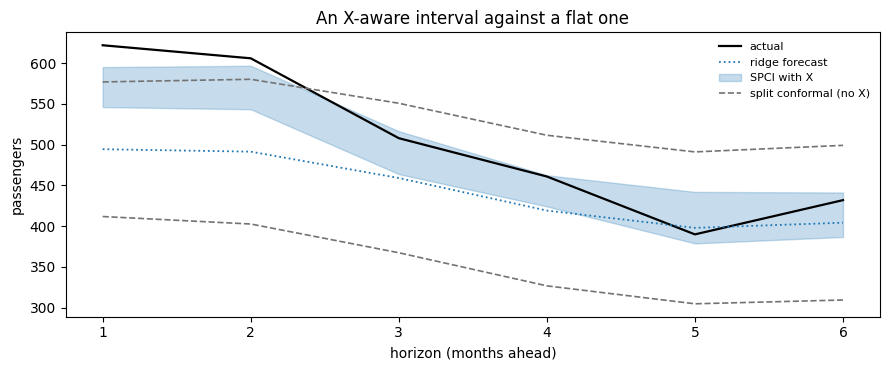

In [ ]:
end = T - HORIZON
X_future = features_at(np.arange(end, end + HORIZON))[None, None]
print("X_future", X_future.shape)

spci_prediction = spci.predict(series[None, :end], X=X_future)
split_prediction = split.predict(series[None, :end])

steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(steps, series[end:], color="k", lw=1.6, label="actual")
ax.plot(steps, spci_prediction.point[0, 0], color="C0", lw=1.3, ls=":", label="ridge forecast")
ax.fill_between(
    steps,
    spci_prediction.interval[0, 0, :, 0],
    spci_prediction.interval[0, 0, :, 1],
    color="C0",
    alpha=0.25,
    label="SPCI with X",
)
ax.plot(
    steps,
    split_prediction.interval[0, 0, :, 0],
    color="0.45",
    lw=1.2,
    ls="--",
    label="split conformal (no X)",
)
ax.plot(steps, split_prediction.interval[0, 0, :, 1], color="0.45", lw=1.2, ls="--")
ax.set_xlabel("horizon (months ahead)")
ax.set_ylabel("passengers")
ax.set_title("An X-aware interval against a flat one")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

In [ ]:
for name, prediction in [("SPCI with X", spci_prediction), ("split conformal", split_prediction)]:
    width = prediction.interval[0, 0, :, 1] - prediction.interval[0, 0, :, 0]
    print(f"{name:18s} width by step {np.round(width, 1)}")

SPCI with X        width by step [49.  53.4 52.7 38.3 63.2 54.6]
split conformal    width by step [165.1 177.5 183.4 184.8 186.3 189.7]


## What the method actually gains

Held out over the last two years, with and without the feature block.

::: {.callout-note}
## `evaluate` does not thread `X`

`diagnostics.evaluate` takes `(fitted, histories, truths)` and no exogenous
argument, so an X-aware holdout has to be rolled by hand. It is six lines, and it
also makes the `predict` / `update` order explicit — which is worth seeing once.
:::

In [ ]:
def roll(fitted, histories, truths, X=None):
    """Predict each holdout window, update online methods, return the intervals."""
    intervals = []
    for k, history in enumerate(histories):
        step_X = None if X is None else X[:, k : k + 1]
        prediction = (
            fitted.predict(history, X=step_X) if step_X is not None else fitted.predict(history)
        )
        intervals.append(prediction.interval[:, 0])
        if fitted.method_.IS_ONLINE:
            truth = truths[:, k : k + 1]
            if step_X is not None:
                fitted.update(prediction.point, truth, X=step_X)
            else:
                fitted.update(prediction.point, truth)
    return np.stack(intervals, axis=1)  # (n_series, n_windows, horizon, 2)


holdout_histories, holdout_truths, holdout_exog = [], [], []
for k in range(N_HOLDOUT, 0, -1):
    end = T - k * HORIZON
    holdout_histories.append(series[None, :end])
    holdout_truths.append(series[None, end : end + HORIZON])
    holdout_exog.append(features_at(np.arange(end, end + HORIZON))[None])
holdout_truths = np.stack(holdout_truths, axis=1)
X_holdout = np.stack(holdout_exog, axis=1)

# The same method config, fitted a second time without X: a separate object.
blind = spci_method.calibrate(forecaster, histories, truths)

for name, fitted, X in [
    ("SPCI with X", spci, X_holdout),
    ("SPCI without X", blind, None),
    ("split conformal", split, None),
]:
    intervals = roll(fitted, holdout_histories, holdout_truths, X)
    covered = (holdout_truths >= intervals[..., 0]) & (holdout_truths <= intervals[..., 1])
    width = intervals[..., 1] - intervals[..., 0]
    print(f"{name:18s} coverage {covered.mean():6.1%}   mean width {width.mean():7.1f}")

SPCI with X        coverage  58.3%   mean width    61.3


SPCI without X     coverage  62.5%   mean width    55.2
split conformal    coverage  83.3%   mean width   181.1


On this problem, the features do not earn their place. SPCI with `X` is *wider*
than SPCI without it (61.3 against 55.2) and covers worse (58.3% against 62.5%),
and both sit far under the 90% target while plain split conformal — which cannot
read `X` at all — covers best at 83.3%.

That is a real result, not a broken example, and it has two causes worth
separating:

- **The features are redundant.** A trend and two Fourier pairs describe where in
  the year each step falls. SPCI's residual window already carries that
  information implicitly, because the last 24 residuals of a seasonal series
  encode the season. Giving a model a feature it can already infer adds variance,
  not signal. Exogenous features pay off when they carry information the residual
  history *cannot* contain — a scheduled promotion, a known outage, a holiday
  calendar that does not repeat annually.
- **The horizon.** SPCI under-covers at multi-step horizons on real series; see
  the warning on the [SPCI page](../methods/spci.html) for the measurement and the
  reason. Both SPCI columns inherit that, with or without `X`.

The transferable lesson is the one this page opened with: thread the features,
then *measure*. `X` is a hypothesis about what drives your uncertainty, and
[diagnostics](diagnostics.html) is how you find out whether it was right.

## Next

- [SPCI](../methods/spci.html) — the method that consumes `X`, in full.
- [Adapters](../adapters/index.html) — writing your own, including the `X` keyword.
- [Diagnostics](diagnostics.html) — measuring whether the features earned their place.